# Import

In [103]:
import gymnasium as gym
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from collections import deque
import random
import torch.optim as optim
import numpy as np

## Un épisode aléatoire

In [104]:
env = gym.make("LunarLander-v3")

etat_actuel, info = env.reset(seed=42)

total_reward = 0.0
steps = 0

while True:
    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    etat_actuel = next_state

    if terminated or truncated:
        break

print("Score total :", total_reward)
print("Nombre de pas :", steps)
print("Terminé :", terminated)
print("Interrompu :", truncated)

env.close()

Score total : -226.2531182337787
Nombre de pas : 124
Terminé : True
Interrompu : False


## Plusieurs épisodes aléatoires

In [105]:
# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
N_EPISODES = 10

# Création de l'environnement sans affichage graphique
env = gym.make("LunarLander-v3")

# Initialisation de la graine aléatoire
env.reset(seed=42)
env.action_space.seed(42)

# On va créer un CSV afin de sauvergarder les résultats
fichier_final = Path("results_random.csv")

# Liste qui contiendra les résultats des épisodes
results = []

# Exécution des épisodes
for episode in range(1, N_EPISODES + 1):

    # Démarrage d'un nouvel épisode
    etat_actuel, info = env.reset()

    # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
    recompense_totale = 0.0
    steps = 0

    # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
    terminated = False
    truncated = False

    # L'agent joue jusqu'à la fin de l'épisode
    while not (terminated or truncated):

        # Choix d'une action aléatoire
        action = env.action_space.sample()

        # Exécution de l'action (on sauvergarde chaque info qu'engendre l'action comme la position, la récompense ou savoir si le module a terminé d'une quelconque façon)
        next_state, reward, terminated, truncated, info = env.step(action)

        # Mise à jour des statistiques
        recompense_totale += reward
        steps += 1

        # Passage au nouvel état
        etat_actuel = next_state

    # On enregistre les résultats de l'épisode
    result = {
        "episode": episode,
        "reward": round(recompense_totale, 2),
        "steps": steps,
        "terminated": terminated,
        "truncated": truncated
    }

    results.append(result)

    # Affichage du résultat
    print(f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

# Fermeture de l'environnement
env.close()

# Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques
with fichier_final.open("w", newline="", encoding="utf-8") as file:

    # Création des 5 colonnes qui sont les différentes paramètres du modèle
    colonnes = ["episode", "reward", "steps", "terminated", "truncated"]

    writer = csv.DictWriter(file, fieldnames=colonnes)

    # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
    writer.writeheader()
    writer.writerows(results)

# Calcul des statistiques globales
mean_reward = sum(r["reward"] for r in results) / len(results)

print("\n------- BILAN -------")
print(f"Nombre d'épisodes : {N_EPISODES}")
print(f"Récompense moyenne : {mean_reward:.2f}")

Épisode 1/10 | Récompense obtenue : -108.55 | Pas utilisés pour terminé : 106 | Terminé ? : True | Interrompu ? : False
Épisode 2/10 | Récompense obtenue : -117.45 | Pas utilisés pour terminé : 75 | Terminé ? : True | Interrompu ? : False
Épisode 3/10 | Récompense obtenue : -304.18 | Pas utilisés pour terminé : 62 | Terminé ? : True | Interrompu ? : False
Épisode 4/10 | Récompense obtenue : -113.35 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 5/10 | Récompense obtenue : -108.74 | Pas utilisés pour terminé : 105 | Terminé ? : True | Interrompu ? : False
Épisode 6/10 | Récompense obtenue : -295.99 | Pas utilisés pour terminé : 87 | Terminé ? : True | Interrompu ? : False
Épisode 7/10 | Récompense obtenue : -116.40 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 8/10 | Récompense obtenue : -222.88 | Pas utilisés pour terminé : 143 | Terminé ? : True | Interrompu ? : False
Épisode 9/10 | Récompense obtenue : -100.74

## Graphiques des résultats

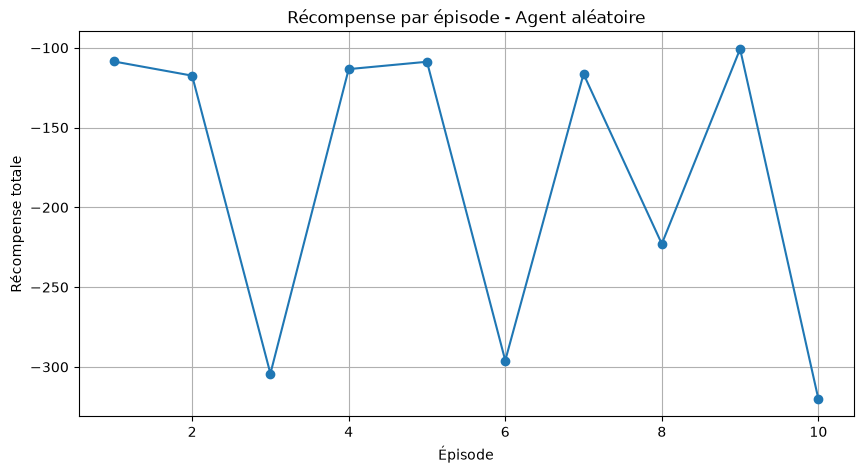

In [106]:
# On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les récompenses par épisode)
episodes = []
rewards = []

# Lecture du fichier CSV
with open("results_random.csv", "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    # Pour chaque ligne du CSV, on ajoute l'épisode et la récompense associée, à la liste    
    for row in reader:
        episodes.append(int(row["episode"]))
        rewards.append(float(row["reward"]))

# Création du graphique
plt.figure(figsize=(10, 5))

# Ordonnées episodes, Abscisses récompenses
plt.plot(episodes, rewards, marker="o")

# Légende du graphique (titre, label X, label Y)
plt.title("Récompense par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

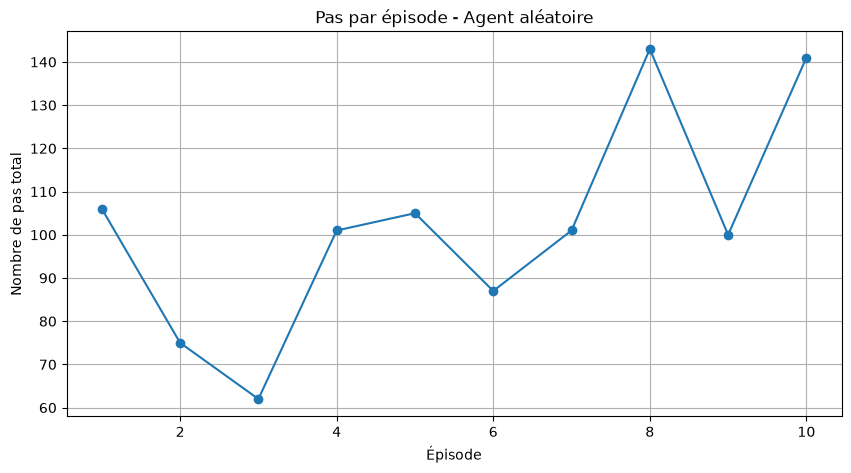

In [107]:
# On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les pas par épisode)
episodes = []
steps = []

# Lecture du fichier CSV
with open("results_random.csv", "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    # Pour chaque ligne du CSV, on ajoute l'épisode et le nombre de pas à la liste
    for ligne in reader:
        episodes.append(int(ligne["episode"]))
        steps.append(float(ligne["steps"]))

# Création du graphique
plt.figure(figsize=(10, 5))

# Ordonnées episodes, Abscisses Steps
plt.plot(episodes, steps, marker="o")

# Légende du graphique (titre, label X, label Y)
plt.title("Pas par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Nombre de pas total")

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

## Entrainement DQN

### Création de l'environnement PyTorch

In [108]:
class DQN(nn.Module):
    def __init__(self, state_size=8, action_size=4):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)

### Epsilon-greedy

In [109]:
def select_action(state, model, epsilon, action_size=4):
    # Exploration : choisir une action au hasard
    if random.random() < epsilon:
        return random.randrange(action_size)

    # Exploitation : choisir la meilleure action selon le réseau
    with torch.no_grad():
        state = torch.tensor(state, dtype=torch.float32)
        q_values = model(state)

    return torch.argmax(q_values).item()

### ReplayBuffer

In [110]:
class ReplayBuffer:

  def __init__(self, capacity):
    self.buffer = deque(maxlen=capacity)

  def __len__(self):
    return len(self.buffer)

  def add(self, experience):
    self.buffer.append(experience)

  def sample(self, batch_size):
    return random.sample(self.buffer, batch_size)

### Train Step

In [111]:
BATCH_SIZE = 50
GAMMA = 0.99
TARGET_UPDATE = 250
steps_done = 0

def train_step():

    # On attend d'avoir assez d'expériences pour former un lot
    if len(buffer) < BATCH_SIZE:
        return None

    # On va venir récupérer le nombre d'expériences de manière aléatoire
    batch = buffer.sample(BATCH_SIZE)

    # On va ensuite séparer les expériences via les paramètres (le zip permet de régrouper tous les élémets de "batch" en un point)
    states, actions, rewards, next_states, terminated, truncated = zip(*batch)

    # Puis on va convertir ces paramètres en tenseurs PyTorch (utilisable par le modèle)
    states = torch.as_tensor(np.asarray(states), dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64).unsqueeze(1)
    rewards = torch.tensor(rewards, dtype=torch.float32)
    next_states = torch.as_tensor(np.asarray(next_states), dtype=torch.float32)
    terminated = torch.tensor(terminated, dtype=torch.float32)

    # 4. Prédictions du réseau principal pour les actions effectuées
    current_q_values = model(states).gather(1, actions).squeeze(1)

    # On calcule les valeurs cibles avec le réseau cible
    with torch.no_grad():
        next_q_values = target_model(next_states)
        max_next_q_values = next_q_values.max(dim=1).values
        target_q_values = (rewards + GAMMA * (1 - terminated) * max_next_q_values)

    # Et on calcule la fonction de perte MSE
    loss = loss_fn(current_q_values, target_q_values)

    # Mise à jour des paramètres du réseau principal
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # Et enfin, on renvoie la valeur de la perte pour pouvoir la suivre
    return loss.item()

### Entrainement du modèle

In [112]:
# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
N_EPISODES = 1250

epsilon = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.997

SEED = 42
random.seed(SEED) 
np.random.seed(SEED) 
torch.manual_seed(SEED)

# Création de l'environnement sans affichage graphique
env = gym.make("LunarLander-v3")

# Initialisation de la graine aléatoire
env.reset(seed=42)
env.action_space.seed(42)

# On va créer un CSV afin de sauvergarder les résultats
fichier_final = Path("results_random.csv")

# Liste qui contiendra les résultats des épisodes
results = []

# Création du modèle DQN
model = DQN()

# Création du modèle cible qui va servir de référence et de comparaison pour le modèle (on l'initialise avec les mêmes paramètres que notre modèle) 
target_model = DQN()
target_model.load_state_dict(model.state_dict())

# Création du buffer, c'est la manière avec laquelle le modèle va se souvenir des éléments.
buffer = ReplayBuffer(100000)

# L'optimiseur va permettre de modifier continuellement le modèle cible afin d'affiner au fil du temps le résultat.
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Création de la loss fonction avec la Mean Squared Error (MSE) qui va comparer la valeur prédite de la valeur cible. 
loss_fn = nn.MSELoss()

# Exécution des épisodes
for episode in range(1, N_EPISODES + 1):

    # Démarrage d'un nouvel épisode
    etat_actuel, info = env.reset()

    # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
    recompense_totale = 0.0
    steps = 0

    # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
    terminated = False
    truncated = False

    # L'agent joue jusqu'à la fin de l'épisode
    while not (terminated or truncated):

        # Initialisation du choix de l'action
        action = select_action(etat_actuel, model, epsilon)

        # Execution de l'action
        next_state, reward, terminated, truncated, info = env.step(action)

        experience = etat_actuel, action, reward, next_state, terminated, truncated
        
        # Enregistrement de la "frame actuel" (la position, les récompenses etc...)
        buffer.add(experience)

        # On met à jour les statistiques
        recompense_totale += reward
        steps += 1
        steps_done += 1

        # On entraîne le réseau principal tous les deux steps.
        if steps_done % 2 == 0:
            loss = train_step()

        # On met à jour le réseau cible périodiquement
        if steps_done % TARGET_UPDATE == 0:
            target_model.load_state_dict(model.state_dict())

        # Et enfin on passe à l'état suivant
        etat_actuel = next_state

    # On enregistre les résultats de l'épisode
    result = {
        "episode": episode,
        "reward": round(recompense_totale, 2),
        "steps": steps,
        "terminated": terminated,
        "truncated": truncated
    }

    # On les ajoute dans la liste results
    results.append(result)

    # On diminue la pourcentage d'élément d'apprentissage pour s'entrainer de plus en plus
    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)

    # Affichage du résultat
    print(f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

# Fermeture de l'environnement
env.close()

# Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques et les tests finaux
with fichier_final.open("w", newline="", encoding="utf-8") as file:

    # Création des 5 colonnes qui sont les différentes paramètres du modèle
    colonnes = ["episode", "reward", "steps", "terminated", "truncated"]

    writer = csv.DictWriter(file, fieldnames=colonnes)

    # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
    writer.writeheader()
    writer.writerows(results)

# Calcul des statistiques globales
mean_reward = sum(r["reward"] for r in results) / len(results)

print("\n------- BILAN -------")
print(f"Nombre d'épisodes : {N_EPISODES}")
print(f"Récompense moyenne : {mean_reward:.2f}")

Épisode 1/1250 | Récompense obtenue : -87.47 | Pas utilisés pour terminé : 117 | Terminé ? : True | Interrompu ? : False
Épisode 2/1250 | Récompense obtenue : -339.71 | Pas utilisés pour terminé : 108 | Terminé ? : True | Interrompu ? : False
Épisode 3/1250 | Récompense obtenue : -306.34 | Pas utilisés pour terminé : 91 | Terminé ? : True | Interrompu ? : False
Épisode 4/1250 | Récompense obtenue : -141.03 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Épisode 5/1250 | Récompense obtenue : -234.43 | Pas utilisés pour terminé : 97 | Terminé ? : True | Interrompu ? : False
Épisode 6/1250 | Récompense obtenue : -146.05 | Pas utilisés pour terminé : 83 | Terminé ? : True | Interrompu ? : False
Épisode 7/1250 | Récompense obtenue : -136.79 | Pas utilisés pour terminé : 103 | Terminé ? : True | Interrompu ? : False
Épisode 8/1250 | Récompense obtenue : -188.97 | Pas utilisés pour terminé : 93 | Terminé ? : True | Interrompu ? : False
Épisode 9/1250 | Récompense ob

### Sauvegarde du modèle en .pth

In [113]:
torch.save(model.state_dict(), "lunarlander_dqn.pth")

print("Modèle sauvegardé !")

Modèle sauvegardé !


### Graphique Avancé de l'apprentissage

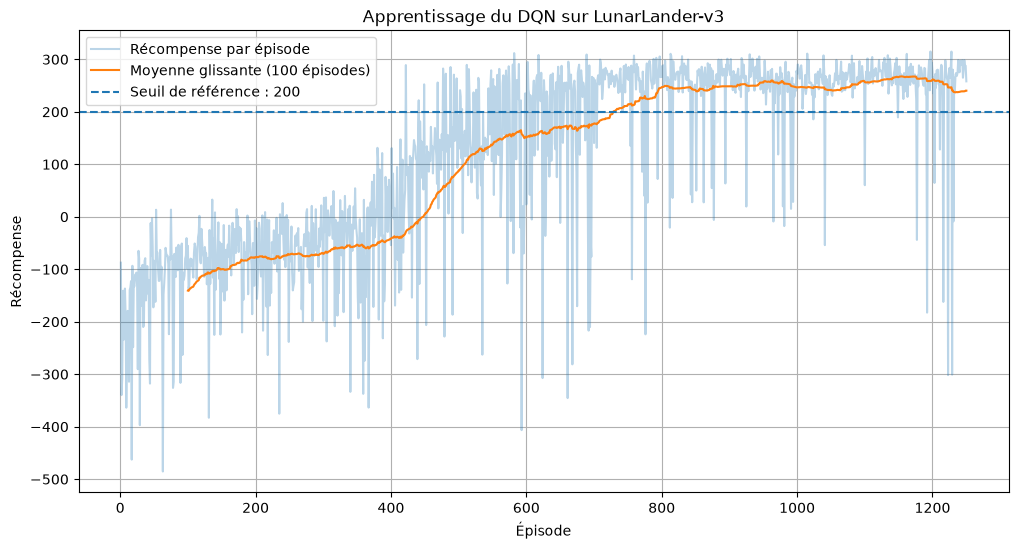

In [114]:
episodes = [result["episode"] for result in results]
rewards = [result["reward"] for result in results]

moving_average = np.convolve(rewards, np.ones(100) / 100, mode="valid")

plt.figure(figsize=(12, 6))

plt.plot(episodes,rewards, alpha=0.3, label="Récompense par épisode")
plt.plot(episodes[100 - 1:], moving_average, label="Moyenne glissante (100 épisodes)")
plt.axhline(y=200,linestyle="--",label="Seuil de référence : 200")

plt.xlabel("Épisode")
plt.ylabel("Récompense")
plt.title("Apprentissage du DQN sur LunarLander-v3")
plt.legend()

plt.grid(True)
plt.show()